# 选股窗口研究：训练 / 验证 / 测试

```
2010 ........ 2020 | 2021  2022  2023 | 2024  2025  2026
     选股数据        |      验证         |       测试
```

**思路**
1. 验证：用截至 2020 年的 1/3/5/10 年数据分别选股，在 2021–23 上比较各种参数。
2. 只根据验证结果选出一组参数，然后**冻结**。
3. 测试：用同样的选股规则、截至 2023 年的数据重新选股，在 2024–26 上**只跑一次**。

**运行前准备**
- 这个 notebook 要放在项目根目录，和 `selection_window_study.py`、`pairs_backtest_engine.py` 在同一个文件夹。
- 从上到下一个 cell 一个 cell 运行（Shift + Enter）。
- 所有函数都写在 `selection_window_study.py` 里，这样多进程在 Mac 上才能正常工作。notebook 只负责一步步调用。

## 第 0 步：导入和检查文件
确认当前文件夹对不对，引擎文件和数据文件在不在。

In [1]:
import importlib, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import selection_window_study as sws
importlib.reload(sws)   # 如果改过 .py 文件，重新运行这个 cell 就会生效

print("当前文件夹:", Path.cwd())
assert Path("pairs_backtest_engine.py").exists(), "找不到 pairs_backtest_engine.py，notebook 要放在项目根目录"
assert sws.DATA_FILE.exists(), f"找不到数据文件 {sws.DATA_FILE}"
print("文件检查通过")

当前文件夹: /Users/liusiming/pairs-trading-strategy
文件检查通过


## 第 1 步：设置参数
- `SELECTION_WINDOWS`：**选股窗口**，用几年数据做协整检验，决定"交易哪几对"。
- `ESTIMATION_WINDOWS`：**滚动窗口**，每个交易年开始前用前几年数据估计 α、β 和 spread 的均值、标准差（z 值要用），决定"这一对怎么交易"。
- 其余是交易规则：entry、exit、止损、最长持仓。

这里列出的所有组合**只在验证集 2021–23 上比较**。想加窗口直接改列表，但组合越多越容易过拟合。

In [2]:
sws.SELECTION_WINDOWS  = [1, 3, 5, 10]
sws.ESTIMATION_WINDOWS = [1, 2, 3, 5]
sws.ENTRY_Z  = [1.5, 2.0, 2.5]
sws.EXIT_Z   = [0.0, 0.5]
sws.STOP_Z   = [None, 3.0]
sws.MAX_HOLD = [None, 60]

COST = 0.001                     # 单边交易成本 10bp
VALIDATION_CUTOFF, VALIDATION_YEARS = 2020, [2021, 2022, 2023]
TEST_CUTOFF, TEST_YEARS = 2023, [2024, 2025, 2026]
MIN_VALIDATION_TRADES = 10       # 交易数少于这个的组合不参与挑选

OUT = sws.OUTPUT_DIR
OUT.mkdir(exist_ok=True)
n_grid = (len(sws.SELECTION_WINDOWS) * len(sws.ESTIMATION_WINDOWS) * len(sws.ENTRY_Z)
          * len(sws.EXIT_Z) * len(sws.STOP_Z) * len(sws.MAX_HOLD))
print("验证阶段参数组合数:", n_grid)

验证阶段参数组合数: 384


## 第 2 步：读取价格数据

In [3]:
prices = sws.load_prices()
print("形状:", prices.shape)
print("日期:", prices.index.min().date(), "到", prices.index.max().date())
display(prices.iloc[:5, :5])

形状: (4245, 485)
日期: 2010-01-04 到 2026-11-17


,A,AAPL,ABBV,ABT,ACGL
Date,,,,,
2010-01-04,19.743519,6.396101,NaN,17.968191,7.601905
2010-01-05,19.529053,6.407160,NaN,17.823011,7.576549
2010-01-06,19.459665,6.305244,NaN,17.922005,7.543795
2010-01-07,19.434433,6.293589,NaN,18.070469,7.499420
2010-01-08,19.428129,6.335429,NaN,18.162849,7.484628


## 第 3 步：验证阶段选股（最慢的一步）
对每个选股窗口（数据都截至 2020-12-31）做三件事：
1. 先对每只股票单独做 ADF 检验，只保留 I(1) 的股票（剔除本身就横盘、平稳的股票）。
2. 对剩下的所有配对做 Engle-Granger 协整检验，多核并行。
3. 做 BH-FDR 校正。

每个窗口大概十几到二十几分钟。**中途中断了没关系**，再运行会从断点继续；已经跑完的窗口会直接读取缓存。

In [4]:
val_screens = {}
for s in sws.SELECTION_WINDOWS:
    val_screens[s] = sws.screen(prices, VALIDATION_CUTOFF, s)

summary = pd.DataFrame([{
    "选股窗口": f"{s}Y",
    "检验配对数": len(df),
    "原始 p<0.01": int((df["P Value"] < 0.01).sum()),
    "原始 p<0.05": int((df["P Value"] < 0.05).sum()),
    "BH 显著": int(df["BH Significant"].sum()),
} for s, df in val_screens.items()])
display(summary)

[cut2020_1Y] window 2020-2020: 253 days, 425 tickers, 90,100 pairs, 90,100 to test
[cut2020_1Y] 500/90,100 elapsed 6s
[cut2020_1Y] 1,000/90,100 elapsed 6s
[cut2020_1Y] 1,500/90,100 elapsed 7s
[cut2020_1Y] 2,000/90,100 elapsed 8s
[cut2020_1Y] 2,500/90,100 elapsed 8s
[cut2020_1Y] 3,000/90,100 elapsed 11s
[cut2020_1Y] 3,500/90,100 elapsed 13s
[cut2020_1Y] 4,000/90,100 elapsed 14s
[cut2020_1Y] 4,500/90,100 elapsed 14s
[cut2020_1Y] 5,000/90,100 elapsed 15s
[cut2020_1Y] 5,500/90,100 elapsed 16s
[cut2020_1Y] 6,000/90,100 elapsed 16s
[cut2020_1Y] 6,500/90,100 elapsed 17s
[cut2020_1Y] 7,000/90,100 elapsed 18s
[cut2020_1Y] 7,500/90,100 elapsed 20s
[cut2020_1Y] 8,000/90,100 elapsed 20s
[cut2020_1Y] 8,500/90,100 elapsed 20s
[cut2020_1Y] 9,000/90,100 elapsed 21s
[cut2020_1Y] 9,500/90,100 elapsed 22s
[cut2020_1Y] 10,000/90,100 elapsed 23s
[cut2020_1Y] 10,500/90,100 elapsed 23s
[cut2020_1Y] 11,000/90,100 elapsed 24s
[cut2020_1Y] 11,500/90,100 elapsed 26s
[cut2020_1Y] 12,000/90,100 elapsed 27s
[cut202

,选股窗口,检验配对数,原始 p<0.01,原始 p<0.05,BH 显著
0,1Y,90100,1255,4814,0
1,3Y,90951,855,3901,2
2,5Y,86320,1385,4943,0
3,10Y,90525,1995,6750,19


## 第 4 步：确定每个窗口要交易的配对
规则：先取 BH 显著的配对；如果不到 5 对，就按原始 p 值从小到大补满 10 对，补进来的标注 **Top-p fill (not BH-significant)**。每只股票最多出现在一对里。

In [5]:
val_pairs = {}
for s in sws.SELECTION_WINDOWS:
    chosen = sws.pick_pairs(val_screens[s])
    chosen.to_csv(OUT / f"validation_pairs_{s}Y.csv", index=False)
    val_pairs[s] = list(zip(chosen["Ticker A"], chosen["Ticker B"]))
    print(f"\n===== {s}Y：{len(chosen)} 对 =====")
    display(chosen[["Ticker A", "Ticker B", "P Value", "BH Adjusted P", "Selection Basis"]])


===== 1Y：10 对 =====


,Ticker A,Ticker B,P Value,BH Adjusted P,Selection Basis
0,TXN,URI,7.128672e-07,0.064163,Top-p fill (not BH-significant)
1,HLT,RJF,2.290062e-06,0.064163,Top-p fill (not BH-significant)
2,ARES,DECK,2.566977e-06,0.064163,Top-p fill (not BH-significant)
3,ROK,WSM,2.848532e-06,0.064163,Top-p fill (not BH-significant)
4,ITW,ZTS,6.626115e-06,0.119403,Top-p fill (not BH-significant)
5,HPQ,HWM,8.138385e-06,0.122211,Top-p fill (not BH-significant)
6,EOG,VLO,1.119232e-05,0.144061,Top-p fill (not BH-significant)
7,MTD,QCOM,2.011471e-05,0.188715,Top-p fill (not BH-significant)
8,ERIE,MPWR,2.094506e-05,0.188715,Top-p fill (not BH-significant)
9,CSX,ON,3.213728e-05,0.254015,Top-p fill (not BH-significant)



===== 3Y：10 对 =====


,Ticker A,Ticker B,P Value,BH Adjusted P,Selection Basis
0,NEE,ZTS,1.319564e-07,0.012002,BH-significant
1,FITB,MGM,1.059373e-06,0.048175,BH-significant
2,FICO,V,1.022279e-05,0.309924,Top-p fill (not BH-significant)
3,MA,PLD,1.410396e-05,0.320692,Top-p fill (not BH-significant)
4,HPE,MTB,2.267974e-05,0.345989,Top-p fill (not BH-significant)
5,APA,SBAC,2.393981e-05,0.345989,Top-p fill (not BH-significant)
6,AKAM,EQIX,3.151549e-05,0.345989,Top-p fill (not BH-significant)
7,EXPD,ISRG,5.554671e-05,0.425421,Top-p fill (not BH-significant)
8,CRL,CVNA,5.962897e-05,0.425421,Top-p fill (not BH-significant)
9,MDLZ,WTW,6.080719e-05,0.425421,Top-p fill (not BH-significant)



===== 5Y：10 对 =====


,Ticker A,Ticker B,P Value,BH Adjusted P,Selection Basis
0,EXPD,ISRG,0.000003,0.146105,Top-p fill (not BH-significant)
1,ACN,LIN,0.000004,0.146105,Top-p fill (not BH-significant)
2,MRSH,PLD,0.000005,0.146105,Top-p fill (not BH-significant)
3,NDAQ,RMD,0.000010,0.191837,Top-p fill (not BH-significant)
4,AON,LNT,0.000011,0.191837,Top-p fill (not BH-significant)
5,CBRE,HLT,0.000015,0.212537,Top-p fill (not BH-significant)
6,GOOGL,KKR,0.000022,0.217844,Top-p fill (not BH-significant)
7,AVGO,MTD,0.000023,0.217844,Top-p fill (not BH-significant)
8,APA,XEL,0.000028,0.217844,Top-p fill (not BH-significant)
9,COST,NEE,0.000032,0.217844,Top-p fill (not BH-significant)



===== 10Y：10 对 =====


,Ticker A,Ticker B,P Value,BH Adjusted P,Selection Basis
0,ADBE,TECH,1.412623e-07,0.008779,BH-significant
1,STE,TDG,2.762439e-07,0.008779,BH-significant
2,DG,FICO,8.059468e-07,0.015315,BH-significant
3,ATO,BSX,1.714353e-06,0.019674,BH-significant
4,LH,MCHP,1.738616e-06,0.019674,BH-significant
5,COO,ORCL,2.355150e-06,0.023689,BH-significant
6,ABT,AJG,3.035103e-06,0.026128,BH-significant
7,BRO,RMD,3.501259e-06,0.026413,BH-significant
8,WTW,XEL,6.081101e-06,0.037062,BH-significant
9,AEE,AON,8.331699e-06,0.041902,BH-significant


## 第 5 步：验证集参数网格（2021–2023）
对每个组合，在 2021、2022、2023 三年里逐年交易：每年开始前用前 N 年数据重新估计 β，这一年内参数不变。组合收益 = 各配对等权平均。

In [6]:
from itertools import product
import time

grid = list(product(sws.SELECTION_WINDOWS, sws.ESTIMATION_WINDOWS,
                    sws.ENTRY_Z, sws.EXIT_Z, sws.STOP_Z, sws.MAX_HOLD))
rows, start = [], time.monotonic()
for k, (s, n, entry, exit_, stop, hold) in enumerate(grid, start=1):
    if not val_pairs[s]:
        continue
    port, log, pr = sws.run_strategy(prices, val_pairs[s], VALIDATION_YEARS,
                                     n, entry, exit_, stop, hold, cost=COST)
    rows.append({"Selection Window": s, "Estimation Window": n, "Entry Z": entry,
                 "Exit Z": exit_, "Stop Z": stop, "Max Hold": hold,
                 **sws.summarize(port, log, pr)})
    if k % 50 == 0 or k == len(grid):
        print(f"{k}/{len(grid)}  已用 {time.monotonic() - start:.0f}s", flush=True)

validation = pd.DataFrame(rows)
validation.to_csv(OUT / "validation_grid.csv", index=False)
print("完成，共", len(validation), "个组合")

50/384  已用 75s
100/384  已用 103s
150/384  已用 130s
200/384  已用 157s
250/384  已用 185s
300/384  已用 213s
350/384  已用 244s
384/384  已用 264s
完成，共 384 个组合


## 第 6 步：哪种选股窗口更好？（稳健的看法）
不只看单个最优组合，而是看每种选股窗口在**所有参数组合**下的表现：Sharpe 中位数、Sharpe 为正的组合占比。这张表比"最优组合"更能回答"哪种选股窗口更好"。

In [7]:
by_window = validation.groupby("Selection Window").agg(
    组合数=("Sharpe", "size"),
    Sharpe中位数=("Sharpe", "median"),
    Sharpe为正占比=("Sharpe", lambda x: float((x > 0).mean())),
    年化收益中位数=("Annualized Return (%)", "median"),
    交易数中位数=("Trades", "median"),
).reset_index()
by_window.to_csv(OUT / "validation_by_selection_window.csv", index=False)
display(by_window.round(3))

# 同样的思路看滚动窗口
by_est = validation.groupby("Estimation Window").agg(
    Sharpe中位数=("Sharpe", "median"),
    Sharpe为正占比=("Sharpe", lambda x: float((x > 0).mean())),
).reset_index()
display(by_est.round(3))

,Selection Window,组合数,Sharpe中位数,Sharpe为正占比,年化收益中位数,交易数中位数
0,1,96,0.098,0.604,0.273,43.0
1,3,96,0.118,0.698,0.344,54.0
2,5,96,-0.434,0.104,-1.350,54.0
3,10,96,-0.211,0.323,-0.680,42.5


,Estimation Window,Sharpe中位数,Sharpe为正占比
0,1,0.058,0.594
1,2,-0.316,0.344
2,3,-0.245,0.281
3,5,0.004,0.510


## 第 7 步：在验证集上选出参数并冻结
在交易数够多的组合里选 Sharpe 最高的。**从这里开始，这组参数就不再改了。**

注意：这是从几百个组合里挑出的最好一个，所以验证集上的 Sharpe 会偏乐观。测试集的结果才是真正的样本外表现。

In [8]:
eligible = validation[validation["Trades"] >= MIN_VALIDATION_TRADES].dropna(subset=["Sharpe"])
top = eligible.sort_values(["Sharpe", "Annualized Return (%)"], ascending=False)
display(top.head(10).round(3))

best = top.iloc[0]
params = dict(
    s=int(best["Selection Window"]), n=int(best["Estimation Window"]),
    entry=float(best["Entry Z"]), exit_=float(best["Exit Z"]),
    stop=None if pd.isna(best["Stop Z"]) else float(best["Stop Z"]),
    hold=None if pd.isna(best["Max Hold"]) else int(best["Max Hold"]),
)
(OUT / "chosen_parameters.json").write_text(json.dumps(params, indent=2))
print("冻结的参数:", params)

,Selection Window,Estimation Window,Entry Z,Exit Z,Stop Z,Max Hold,Total Return (%),Annualized Return (%),Volatility (%),Sharpe,Max Drawdown (%),Trades,Win Rate (%),Avg Trade Return (%),Avg Annual Turnover,Top-5 Trades Share of P&L (%),Pair-Years Traded
99,3,1,1.5,0.0,3.0,60.0,10.703,3.461,3.321,1.041,-3.404,68,48.529,1.626,4.548,62.316,30
97,3,1,1.5,0.0,NaN,60.0,11.506,3.712,3.955,0.941,-4.435,68,63.235,1.821,4.580,57.878,30
7,1,1,1.5,0.5,3.0,60.0,7.386,2.414,3.242,0.752,-2.731,75,57.333,1.028,5.192,72.750,30
125,3,2,1.5,0.5,NaN,60.0,7.808,2.548,3.652,0.707,-6.050,81,64.198,1.063,5.410,91.663,30
111,3,1,2.0,0.5,3.0,60.0,6.088,1.998,2.890,0.699,-3.552,57,47.368,1.100,3.821,98.424,30
103,3,1,1.5,0.5,3.0,60.0,6.474,2.122,3.107,0.691,-3.592,75,50.667,0.946,4.994,91.315,30
107,3,1,2.0,0.0,3.0,60.0,6.117,2.007,2.985,0.680,-3.552,53,43.396,1.141,3.539,106.500,30
101,3,1,1.5,0.5,NaN,60.0,7.993,2.607,3.901,0.679,-5.119,80,65.000,1.152,5.298,74.015,30
98,3,1,1.5,0.0,3.0,NaN,7.408,2.420,3.635,0.676,-4.762,68,48.529,1.205,4.539,97.667,30
109,3,1,2.0,0.5,NaN,60.0,7.062,2.310,3.718,0.633,-3.737,61,60.656,1.319,4.073,84.488,30


冻结的参数: {'s': 3, 'n': 1, 'entry': 1.5, 'exit_': 0.0, 'stop': 3.0, 'hold': 60}


## 第 8 步：entry / exit 敏感性热力图（验证集）
其他参数固定为选中的值，只改 entry 和 exit，看 Sharpe 怎么变。如果颜色变化很剧烈，说明策略对阈值很敏感，这一点要写进报告。

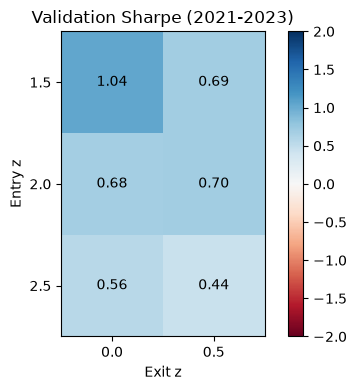

In [9]:
v = validation
mask = ((v["Selection Window"] == params["s"]) & (v["Estimation Window"] == params["n"])
        & (v["Stop Z"].fillna(-1) == (params["stop"] if params["stop"] is not None else -1))
        & (v["Max Hold"].fillna(-1) == (params["hold"] if params["hold"] is not None else -1)))
sens = v[mask].pivot(index="Entry Z", columns="Exit Z", values="Sharpe")

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(sens.to_numpy(dtype=float), cmap="RdBu", vmin=-2, vmax=2)
ax.set_xticks(range(len(sens.columns)), [str(c) for c in sens.columns])
ax.set_yticks(range(len(sens.index)), [str(i) for i in sens.index])
for i in range(sens.shape[0]):
    for j in range(sens.shape[1]):
        ax.text(j, i, f"{sens.iat[i, j]:.2f}", ha="center", va="center")
ax.set_xlabel("Exit z"); ax.set_ylabel("Entry z"); ax.set_title("Validation Sharpe (2021-2023)")
fig.colorbar(im, ax=ax); fig.tight_layout()
fig.savefig(OUT / "validation_entry_exit_heatmap.png", dpi=150)
plt.show()

## 第 9 步：测试阶段选股（截至 2023 年）
用同样的选股窗口长度，换成截至 2023-12-31 的数据**重新选一次股**。只需要跑一个窗口。

In [10]:
test_screen = sws.screen(prices, TEST_CUTOFF, params["s"])
test_chosen = sws.pick_pairs(test_screen)
test_chosen.to_csv(OUT / "test_pairs.csv", index=False)
test_pairs = list(zip(test_chosen["Ticker A"], test_chosen["Ticker B"]))
display(test_chosen[["Ticker A", "Ticker B", "P Value", "BH Adjusted P", "Selection Basis"]])

[cut2023_3Y] window 2021-2023: 753 days, 398 tickers, 79,003 pairs, 79,003 to test
[cut2023_3Y] 500/79,003 elapsed 44s
[cut2023_3Y] 1,000/79,003 elapsed 44s
[cut2023_3Y] 1,500/79,003 elapsed 46s
[cut2023_3Y] 2,000/79,003 elapsed 47s
[cut2023_3Y] 2,500/79,003 elapsed 48s
[cut2023_3Y] 3,000/79,003 elapsed 50s
[cut2023_3Y] 3,500/79,003 elapsed 52s
[cut2023_3Y] 4,000/79,003 elapsed 53s
[cut2023_3Y] 4,500/79,003 elapsed 58s
[cut2023_3Y] 5,000/79,003 elapsed 58s
[cut2023_3Y] 5,500/79,003 elapsed 59s
[cut2023_3Y] 6,000/79,003 elapsed 61s
[cut2023_3Y] 6,500/79,003 elapsed 62s
[cut2023_3Y] 7,000/79,003 elapsed 63s
[cut2023_3Y] 7,500/79,003 elapsed 65s
[cut2023_3Y] 8,000/79,003 elapsed 66s
[cut2023_3Y] 8,500/79,003 elapsed 71s
[cut2023_3Y] 9,000/79,003 elapsed 71s
[cut2023_3Y] 9,500/79,003 elapsed 72s
[cut2023_3Y] 10,000/79,003 elapsed 73s
[cut2023_3Y] 10,500/79,003 elapsed 74s
[cut2023_3Y] 11,000/79,003 elapsed 76s
[cut2023_3Y] 11,500/79,003 elapsed 78s
[cut2023_3Y] 12,000/79,003 elapsed 79s
[c

,Ticker A,Ticker B,P Value,BH Adjusted P,Selection Basis
0,OXY,SWKS,4.499541e-07,0.035548,BH-significant
1,INCY,VRSK,1.322021e-06,0.052222,Top-p fill (not BH-significant)
2,EBAY,TROW,4.818116e-06,0.126882,Top-p fill (not BH-significant)
3,AMAT,AOS,1.487756e-05,0.235074,Top-p fill (not BH-significant)
4,BBY,IVZ,4.549456e-05,0.409669,Top-p fill (not BH-significant)
5,AZO,SKYD,5.977662e-05,0.444252,Top-p fill (not BH-significant)
6,CNP,KO,7.608120e-05,0.500887,Top-p fill (not BH-significant)
7,EW,UDR,1.037149e-04,0.630292,Top-p fill (not BH-significant)
8,MA,PHM,1.258417e-04,0.639577,Top-p fill (not BH-significant)
9,EOG,TWLO,1.468253e-04,0.639577,Top-p fill (not BH-significant)


## 第 10 步：样本外测试（2024–2026，只跑一次）
用冻结的参数分别跑验证期和测试期，做成样本内 vs 样本外对比表。

In [11]:
run_args = (params["n"], params["entry"], params["exit_"], params["stop"], params["hold"])
val_port, val_log, val_pr = sws.run_strategy(prices, val_pairs[params["s"]], VALIDATION_YEARS, *run_args, cost=COST)
test_port, test_log, test_pr = sws.run_strategy(prices, test_pairs, TEST_YEARS, *run_args, cost=COST)

is_oos = pd.DataFrame([
    {"Period": "验证 2021-2023（参数在这里选，算样本内）", **sws.summarize(val_port, val_log, val_pr)},
    {"Period": "测试 2024-2026（样本外）", **sws.summarize(test_port, test_log, test_pr)},
]).set_index("Period")
is_oos.to_csv(OUT / "in_sample_vs_out_of_sample.csv")
display(is_oos.T.round(3))

yearly = test_port.groupby(test_port.index.year).apply(lambda r: ((1 + r).prod() - 1) * 100)
print("测试期每年收益 (%):")
display(yearly.round(2).rename("Return (%)").to_frame())

Period,验证 2021-2023（参数在这里选，算样本内）,测试 2024-2026（样本外）
Total Return (%),10.703,-1.451
Annualized Return (%),3.461,-0.508
Volatility (%),3.321,3.066
Sharpe,1.041,-0.151
Max Drawdown (%),-3.404,-6.196
Trades,68.000,64.000
Win Rate (%),48.529,43.750
Avg Trade Return (%),1.626,-0.170
Avg Annual Turnover,4.548,4.386
Top-5 Trades Share of P&L (%),62.316,NaN


测试期每年收益 (%):


,Return (%)
Date,
2024,1.10
2025,0.21
2026,-2.73


## 第 11 步：组合净值曲线

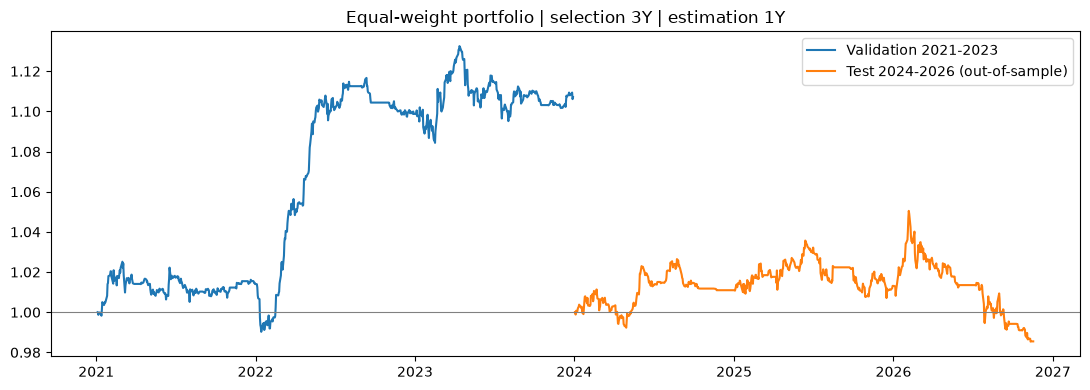

In [12]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot((1 + val_port).cumprod(), label="Validation 2021-2023")
ax.plot((1 + test_port).cumprod(), label="Test 2024-2026 (out-of-sample)")
ax.axhline(1, color="grey", lw=0.8)
ax.set_title(f"Equal-weight portfolio | selection {params['s']}Y | estimation {params['n']}Y")
ax.legend(); fig.tight_layout()
fig.savefig(OUT / "portfolio_equity_curve.png", dpi=150)
plt.show()

## 第 12 步：交易记录，利润是否集中在少数几笔？
`Contribution (%)` 是每笔交易对这一对当年收益的贡献。

In [13]:
test_log.to_csv(OUT / "test_trade_log.csv", index=False)
display(test_log[["Pair", "Year", "Entry Date", "Exit Date", "Direction", "Holding Days",
                  "Net P&L", "Trade Return (%)", "Contribution (%)", "Exit Reason"]].round(3))
print("各平仓原因次数:")
display(test_log["Exit Reason"].value_counts())
print("各配对总贡献 (%):")
display(test_log.groupby("Pair")["Contribution (%)"].sum().sort_values().round(2))

/var/folders/55/bpnz_y1d7h983b05s9zgmpbw0000gn/T/ipykernel_56946/2415232621.py:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  "Net P&L", "Trade Return (%)", "Contribution (%)", "Exit Reason"]].round(3))


,Pair,Year,Entry Date,Exit Date,Direction,Holding Days,Net P&L,Trade Return (%),Contribution (%),Exit Reason
0,OXY-SWKS,2024,2024-01-11,2024-03-04,1,35,3.348,5.745,5.463,Mean reversion
1,OXY-SWKS,2024,2024-04-01,2024-04-08,-1,5,-2.262,-3.353,-3.692,Stop loss
2,OXY-SWKS,2024,2024-08-06,2024-09-09,1,23,-3.841,-6.666,-6.267,Stop loss
3,INCY-VRSK,2024,2024-01-03,2024-03-06,-1,43,6.336,4.482,4.471,Mean reversion
4,INCY-VRSK,2024,2024-04-05,2024-04-26,1,15,-5.901,-4.598,-4.164,Stop loss
...,...,...,...,...,...,...,...,...,...,...
59,MA-PHM,2026,2026-01-16,2026-02-17,1,20,-29.260,-4.453,-4.371,Stop loss
60,MA-PHM,2026,2026-08-25,2026-09-23,-1,20,26.977,3.748,4.030,Mean reversion
61,MA-PHM,2026,2026-10-12,2026-10-16,-1,4,-21.512,-3.080,-3.213,Stop loss
62,EOG-TWLO,2026,2026-01-08,2026-02-05,1,19,8.239,7.790,7.669,Mean reversion


各平仓原因次数:


Exit Reason
Stop loss          36
Mean reversion     24
Max holding         3
End of backtest     1
Name: count, dtype: int64

各配对总贡献 (%):


Pair
EBAY-TROW   -13.52
OXY-SWKS     -8.56
INCY-VRSK    -8.14
MA-PHM       -6.36
CNP-KO       -5.93
BBY-IVZ      -2.28
AZO-SKYD      1.70
AMAT-AOS      3.63
EW-UDR       10.46
EOG-TWLO     15.74
Name: Contribution (%), dtype: float64

## 第 13 步：交易成本敏感性（测试集，只做展示，不用来选参数）
回答 PDF 里的 "Are profits destroyed by transaction costs?"。

In [14]:
cost_rows = []
for c in [0.0, 0.0005, 0.001, 0.002, 0.003]:
    p, l, r = sws.run_strategy(prices, test_pairs, TEST_YEARS, *run_args, cost=c)
    cost_rows.append({"单边成本 (bp)": c * 1e4, **sws.summarize(p, l, r)})
cost_table = pd.DataFrame(cost_rows)
cost_table.to_csv(OUT / "test_cost_sensitivity.csv", index=False)
display(cost_table[["单边成本 (bp)", "Annualized Return (%)", "Sharpe", "Max Drawdown (%)", "Trades"]].round(3))

,单边成本 (bp),Annualized Return (%),Sharpe,Max Drawdown (%),Trades
0,0.0,-0.051,-0.001,-5.868,64
1,5.0,-0.280,-0.076,-6.032,64
2,10.0,-0.508,-0.151,-6.196,64
3,20.0,-0.963,-0.301,-6.523,64
4,30.0,-1.416,-0.451,-6.857,64


## 第 14 步：配对在测试期还协整吗？
回答 PDF 里的 "Do pairs remain cointegrated out of sample?"：只用 2024–26 的数据重新做 Engle-Granger 检验。

In [15]:
from statsmodels.tsa.stattools import coint
window = prices.loc[f"{TEST_YEARS[0]}-01-01":f"{TEST_YEARS[-1]}-12-31"]
persist = []
for a, b in test_pairs:
    d = window[[a, b]].dropna()
    p = float(coint(d[a], d[b], trend="c", autolag="aic")[1]) if len(d) > 100 else np.nan
    persist.append({"Pair": f"{a}-{b}", "测试期 EG p 值": p, "仍然 p<0.05": p < 0.05})
persist = pd.DataFrame(persist)
persist.to_csv(OUT / "test_cointegration_persistence.csv", index=False)
display(persist.round(4))

,Pair,测试期 EG p 值,仍然 p<0.05
0,OXY-SWKS,0.4587,False
1,INCY-VRSK,0.4670,False
2,EBAY-TROW,0.9215,False
3,AMAT-AOS,0.6582,False
4,BBY-IVZ,0.5825,False
5,AZO-SKYD,0.0420,True
6,CNP-KO,0.7928,False
7,EW-UDR,0.1246,False
8,MA-PHM,0.7854,False
9,EOG-TWLO,0.1904,False


## 跑完之后
所有结果都在 `selection_window_study_outputs/` 文件夹里。最值得先看的三份：
- `validation_by_selection_window.csv`：哪种选股窗口更好（第 6 步）
- `in_sample_vs_out_of_sample.csv`：验证 vs 测试（第 10 步）
- `test_cointegration_persistence.csv`：配对在测试期是否还协整（第 14 步）